# 05 · Validación y ajuste de parámetros (tarea 2.3, CRISP-DM fase 4)

**Solo se usa el conjunto de VALIDACIÓN.** El de prueba no se carga. Plan de prueba fijado de antemano en `docs/sprint2/plan_evaluacion.md` (commit 512eecd).

Modelos (paquetes de la tarea 2.2): **FaceNet VGGFace2 congelado (final)** y **control (a2) ResNet-18 ImageNet**.

Contenido:
1. Impostores internos: registradas contra la plantilla de otra registrada.
2. Coseno frente a euclídea, y plantilla media frente a varias plantillas por usuario.
3. Robustez: brillo, contraste, desenfoque, JPEG, rotación leve y oclusión parcial.
4. Umbral por FAR objetivo con margen (no por EER).
5. Agregación de varios fotogramas para el video (simulación con fotos de validación).

**Regla del umbral, definida antes de calcularlo:**
- FAR objetivo **≤ 0,1 %** sobre todas las comparaciones impostoras de validación, externas más internas (6 456 + 7 015 = 13 471).
- Con 13 471 comparaciones, 0,1 % equivale a unas 13 aceptaciones, así que es medible. Un objetivo de 0,01 % equivaldría a una sola aceptación y no sería estimable con fiabilidad.
- **Margen de robustez:** el umbral propuesto es el *mayor* de los umbrales que cumplen FAR ≤ 0,1 % en cada condición (limpia y cada perturbación).
  Así el FAR objetivo se mantiene aunque las imágenes impostoras se degraden. Después se reporta el FRR resultante en cada condición y la distancia a las puntuaciones extremas.

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from src import config as C, data as D, models as M, metrics as MT, verification as V, pipeline as P, robustness as R
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
DEV = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True})
FAR_OBJ = 0.001
sp = D.load_split_table()
cache = np.load(C.DATA_PROCESSED / "faces160.npz", allow_pickle=True)
pos = {f: k for k, f in enumerate(cache["filename"])}
REG = sorted(sp.loc[sp.role == "registrada", "person"].unique())
tr = sp[sp.split == "train"].reset_index(drop=True); va = sp[sp.split == "val"].reset_index(drop=True)
assert set(sp.split.unique()) == {"train", "val", "test"} and (va.split == "val").all()
X_tr = cache["X"][[pos[f] for f in tr.filename]]; X_va = cache["X"][[pos[f] for f in va.filename]]
del cache
PKG = {"facenet": C.MODELS_DIR / "verificador_facenet_vggface2", "control_a2": C.MODELS_DIR / "control_resnet18_imagenet"}
NOM = {"facenet": "FaceNet VGGFace2", "control_a2": "Control (a2) ResNet-18 ImageNet"}
VF = {k: P.Verifier(p, device=DEV) for k, p in PKG.items()}
def emb(k, X): return np.concatenate([VF[k].embed(X[i:i+128]).cpu().numpy() for i in range(0, len(X), 128)])
E_tr = {k: emb(k, X_tr) for k in VF}
print(f"train {len(tr)} | val {len(va)} ({(va.role=='registrada').sum()} genuinas, {(va.role!='registrada').sum()} de impostoras) | prueba: no se carga")

train 1362 | val 574 (305 genuinas, 269 de impostoras) | prueba: no se carga


## 1. Impostores internos y pares más difíciles (imágenes limpias)

In [2]:
E_va = {k: emb(k, X_va) for k in VF}
SC = {}
for k in VF:
    S = V.strategy_matrix(E_va[k], E_tr[k], tr.person.values, REG, "media_coseno")
    d = np.abs(S - E_va[k] @ VF[k].T.cpu().numpy().T).max()
    print(f"{NOM[k]}: dif. máx. entre plantilla recalculada (TorchScript) y la del paquete (red original, 2.2): {d:.1e}")
    assert d < 1e-3
    SC[k] = V.split_scores(S, va.person.values, va.role.values, REG)
filas = []
for k, sc in SC.items():
    g, e, i = sc["genuinas"], sc["impostoras"], sc["internas"]; ei = np.r_[e, i]
    filas.append({"modelo": NOM[k], "genuina_min": g.min(), "genuina_p1": np.percentile(g, 1), "genuina_mediana": np.median(g),
                  "imp_externa_max": e.max(), "imp_interna_max": i.max(), "imp_externa_p99.9": np.percentile(e, 99.9),
                  "imp_interna_p99.9": np.percentile(i, 99.9), "margen_externas": g.min() - e.max(), "margen_ext+int": g.min() - ei.max(),
                  "EER_externas_%": MT.eer(g, e)[0]*100, "EER_internas_%": MT.eer(g, i)[0]*100, "EER_ext+int_%": MT.eer(g, ei)[0]*100,
                  "AUC_ext+int": MT.auc(g, ei), "n_gen": len(g), "n_ext": len(e), "n_int": len(i)})
t1 = pd.DataFrame(filas); t1.to_csv(C.DOCS / "05_impostores_internos.csv", index=False); t1.round(4).T

FaceNet VGGFace2: dif. máx. entre plantilla recalculada (TorchScript) y la del paquete (red original, 2.2): 2.5e-05
Control (a2) ResNet-18 ImageNet: dif. máx. entre plantilla recalculada (TorchScript) y la del paquete (red original, 2.2): 5.4e-07


,0,1
modelo,FaceNet VGGFace2,Control (a2) ResNet-18 ImageNet
genuina_min,0.607,0.6224
genuina_p1,0.6387,0.6821
genuina_mediana,0.8672,0.9274
imp_externa_max,0.511,0.9122
imp_interna_max,0.583,0.8553
imp_externa_p99.9,0.422,0.883
imp_interna_p99.9,0.55,0.7788
margen_externas,0.096,-0.2898
margen_ext+int,0.024,-0.2898


In [3]:
def pares_dificiles(k, n=8):
    sc = SC[k]; rows = []
    for tipo in ["impostoras", "internas"]:
        pr = sc[tipo + "_pares"]; s = sc[tipo]
        for j in np.argsort(-s)[:n]:
            rows.append({"tipo": "externa" if tipo == "impostoras" else "interna", "foto": va.filename[pr[j, 0]],
                         "persona_real": va.person[pr[j, 0]], "dice_ser": REG[pr[j, 1]], "puntuacion": s[j]})
    pr = sc["genuinas_pares"]; s = sc["genuinas"]
    for j in np.argsort(s)[:n]:
        rows.append({"tipo": "genuina (más baja)", "foto": va.filename[pr[j, 0]], "persona_real": va.person[pr[j, 0]],
                     "dice_ser": REG[pr[j, 1]], "puntuacion": s[j]})
    return pd.DataFrame(rows)
dif = pares_dificiles("facenet"); dif.to_csv(C.DOCS / "05_pares_dificiles_facenet.csv", index=False); dif.round(3)

,tipo,foto,persona_real,dice_ser,puntuacion
0,externa,Elizabeth Olsen_7.jpg,Elizabeth Olsen,Alexandra Daddario,0.511
1,externa,Henry Cavill_17.jpg,Henry Cavill,Zac Efron,0.490
2,externa,Henry Cavill_55.jpg,Henry Cavill,Zac Efron,0.455
3,externa,Henry Cavill_7.jpg,Henry Cavill,Brad Pitt,0.446
4,externa,Elizabeth Olsen_70.jpg,Elizabeth Olsen,Jessica Alba,0.434
5,externa,Henry Cavill_100.jpg,Henry Cavill,Zac Efron,0.430
6,externa,Elizabeth Olsen_26.jpg,Elizabeth Olsen,Jessica Alba,0.422
7,externa,Elizabeth Olsen_39.jpg,Elizabeth Olsen,Claire Holt,0.422
8,interna,Hrithik Roshan_49.jpg,Hrithik Roshan,Vijay Deverakonda,0.583
9,interna,Hrithik Roshan_68.jpg,Hrithik Roshan,Vijay Deverakonda,0.576


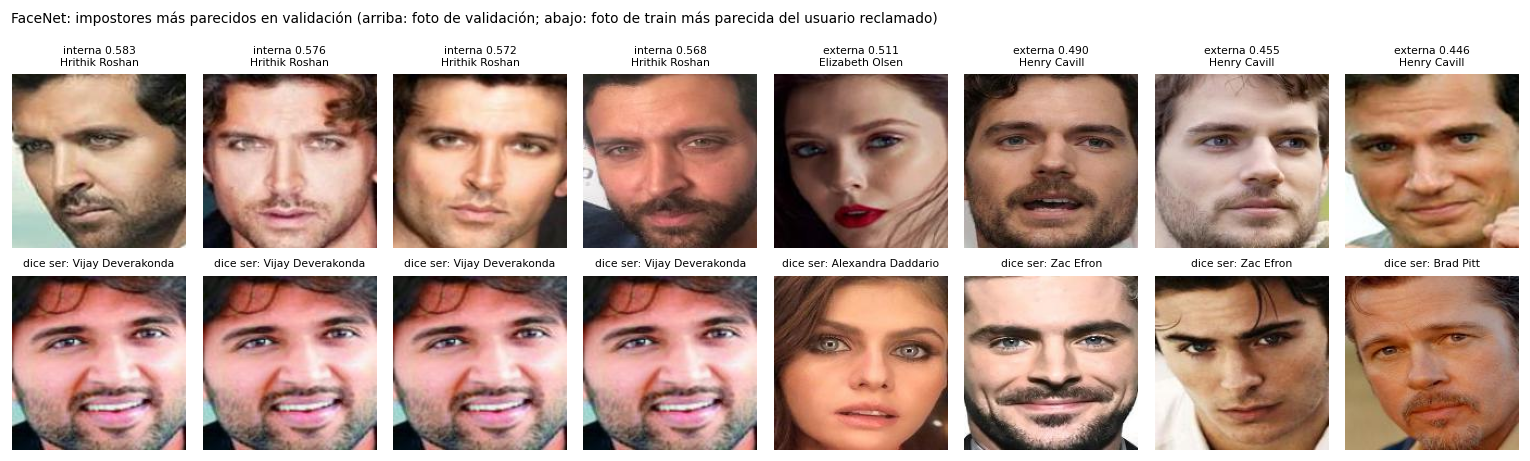

In [4]:
top = pd.concat([dif[dif.tipo == "interna"].head(4), dif[dif.tipo == "externa"].head(4)])
fig, axes = plt.subplots(2, 8, figsize=(14, 4.4))
for c, (_, r) in enumerate(top.iterrows()):
    # foto de train de la persona reclamada más parecida a la foto de validación
    i = va.index[va.filename == r.foto][0]; m = (tr.person == r.dice_ser).values
    jn = np.argmax(E_tr["facenet"][m] @ E_va["facenet"][i])
    axes[0, c].imshow(X_va[i]); axes[1, c].imshow(X_tr[m][jn])
    axes[0, c].set_title(f"{r.tipo} {r.puntuacion:.3f}\n{r.persona_real}", fontsize=7)
    axes[1, c].set_title(f"dice ser: {r.dice_ser}", fontsize=7)
for a in axes.ravel(): a.axis("off")
plt.suptitle("FaceNet: impostores más parecidos en validación (arriba: foto de validación; abajo: foto de train más parecida del usuario reclamado)", x=0.01, ha="left", fontsize=9)
plt.tight_layout(); plt.savefig(C.FIGS / "05_pares_dificiles_facenet.png"); plt.show()

## 2. Robustez: perturbaciones de las imágenes de validación (genuinas e impostoras)

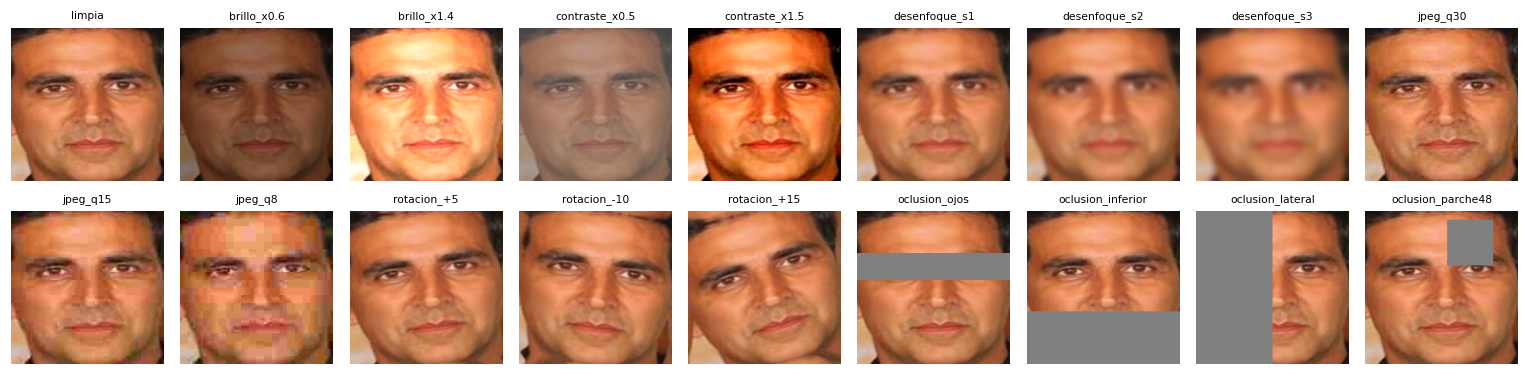

In [5]:
ex = X_va[np.where(va.person == REG[0])[0][0]]
names = list(R.PERTURBATIONS)
fig, axes = plt.subplots(2, 9, figsize=(14, 3.6))
for a, n in zip(axes.ravel(), names):
    a.imshow(R.apply(n, ex[None])[0]); a.set_title(n, fontsize=7); a.axis("off")
plt.tight_layout(); plt.savefig(C.FIGS / "05_perturbaciones_ejemplo.png"); plt.show()

In [6]:
t0 = time.time()
EP = {k: {} for k in VF}
for n in names:
    Xp = R.apply(n, X_va)
    for k in VF: EP[k][n] = emb(k, Xp)
print(f"{len(names)} condiciones × {len(X_va)} imágenes × 2 modelos en {time.time()-t0:.0f} s")
def scores_cond(k, n, strategy="media_coseno"):
    S = V.strategy_matrix(EP[k][n], E_tr[k], tr.person.values, REG, strategy)
    sc = V.split_scores(S, va.person.values, va.role.values, REG)
    return sc["genuinas"], np.r_[sc["impostoras"], sc["internas"]], sc
SCOND = {k: {n: scores_cond(k, n) for n in names} for k in VF}

18 condiciones × 574 imágenes × 2 modelos en 39 s


## 3. Umbral por FAR objetivo (≤ 0,1 %) con margen de robustez

In [7]:
UMB = {}
for k in VF:
    g0, i0, _ = SCOND[k]["limpia"]
    t_cond = {n: V.threshold_for_far(SCOND[k][n][1], FAR_OBJ) for n in names}
    t_star = max(t_cond.values()); n_star = max(t_cond, key=t_cond.get)
    cand = {"EER (limpia)": MT.eer(g0, i0)[1], "centro del hueco limpio": (g0.min() + i0.max()) / 2,
            "FAR≤0,1 % (solo limpia)": t_cond["limpia"], "FAR≤0,1 % (peor condición) = PROPUESTO": t_star}
    UMB[k] = {"t_cond": t_cond, "t_star": t_star, "cond_peor": n_star, "candidatos": cand}
    print(f"{NOM[k]}: umbral propuesto {t_star:.4f} (lo fija la condición '{n_star}')")
rows = []
for k in VF:
    for cname, t in UMB[k]["candidatos"].items():
        for n in names:
            g, i, _ = SCOND[k][n]; far, frr = MT.far_frr(g, i, t)
            rows.append({"modelo": NOM[k], "umbral": cname, "valor": t, "condicion": n, "FAR_%": far*100, "FRR_%": frr*100})
cand = pd.DataFrame(rows); cand.to_csv(C.DOCS / "05_umbrales_candidatos.csv", index=False)
resumen = cand.groupby(["modelo", "umbral", "valor"]).apply(lambda d: pd.Series({
    "FAR_limpia_%": d.loc[d.condicion=="limpia","FAR_%"].iloc[0], "FRR_limpia_%": d.loc[d.condicion=="limpia","FRR_%"].iloc[0],
    "FAR_peor_%": d["FAR_%"].max(), "cond_FAR_peor": d.loc[d["FAR_%"].idxmax(), "condicion"],
    "FRR_peor_%": d["FRR_%"].max(), "cond_FRR_peor": d.loc[d["FRR_%"].idxmax(), "condicion"],
    "FRR_medio_perturbadas_%": d.loc[d.condicion!="limpia","FRR_%"].mean()}), include_groups=False).reset_index()
resumen.to_csv(C.DOCS / "05_umbrales_resumen.csv", index=False); resumen.round(3)

FaceNet VGGFace2: umbral propuesto 0.5514 (lo fija la condición 'rotacion_+15')
Control (a2) ResNet-18 ImageNet: umbral propuesto 0.8769 (lo fija la condición 'rotacion_-10')


,modelo,umbral,valor,FAR_limpia_%,FRR_limpia_%,FAR_peor_%,cond_FAR_peor,FRR_peor_%,cond_FRR_peor,FRR_medio_perturbadas_%
0,Control (a2) ResNet-18 ImageNet,EER (limpia),0.754,2.836,2.951,2.836,limpia,66.885,desenfoque_s3,19.074
1,Control (a2) ResNet-18 ImageNet,"FAR≤0,1 % (peor condición) = PROPUESTO",0.877,0.074,21.967,0.097,rotacion_-10,97.049,jpeg_q8,54.195
2,Control (a2) ResNet-18 ImageNet,"FAR≤0,1 % (solo limpia)",0.870,0.097,19.016,0.111,brillo_x0.6,95.738,desenfoque_s3,51.070
3,Control (a2) ResNet-18 ImageNet,centro del hueco limpio,0.767,2.182,3.607,2.182,limpia,72.131,desenfoque_s3,21.061
4,FaceNet VGGFace2,EER (limpia),0.607,0.000,0.000,0.022,rotacion_+15,44.590,oclusion_ojos,7.676
5,FaceNet VGGFace2,"FAR≤0,1 % (peor condición) = PROPUESTO",0.551,0.052,0.000,0.097,rotacion_+15,28.525,oclusion_ojos,4.783
6,FaceNet VGGFace2,"FAR≤0,1 % (solo limpia)",0.547,0.097,0.000,0.119,rotacion_+15,26.557,oclusion_ojos,4.436
7,FaceNet VGGFace2,centro del hueco limpio,0.595,0.000,0.000,0.022,jpeg_q8,40.656,oclusion_ojos,6.943


In [8]:
rob = []
for k in VF:
    g0 = SCOND[k]["limpia"][0]; t = UMB[k]["t_star"]
    for n in names:
        g, i, _ = SCOND[k][n]; far, frr = MT.far_frr(g, i, t)
        rob.append({"modelo": NOM[k], "condicion": n, "genuina_media": g.mean(), "caida_media_genuina": g0.mean() - g.mean(),
                    "caida_max_genuina": (g0 - g).max(), "genuina_min": g.min(), "imp_max": i.max(),
                    "umbral_condicion_FAR0.1%": UMB[k]["t_cond"][n], "FAR_%_en_propuesto": far*100, "FRR_%_en_propuesto": frr*100,
                    "EER_%": MT.eer(g, i)[0]*100})
rob = pd.DataFrame(rob); rob.to_csv(C.DOCS / "05_robustez.csv", index=False)
rob[rob.modelo == NOM["facenet"]].drop(columns="modelo").round(4)

,condicion,genuina_media,caida_media_genuina,caida_max_genuina,genuina_min,imp_max,umbral_condicion_FAR0.1%,FAR_%_en_propuesto,FRR_%_en_propuesto,EER_%
0,limpia,0.8521,0.0000,0.0000,0.6070,0.5830,0.5469,0.0520,0.0000,0.0000
1,brillo_x0.6,0.8434,0.0087,0.1189,0.5975,0.5941,0.5284,0.0297,0.0000,0.0000
2,brillo_x1.4,0.8301,0.0220,0.3110,0.4891,0.6104,0.5482,0.0817,0.9836,0.3235
3,contraste_x0.5,0.8368,0.0153,0.1409,0.5327,0.5897,0.5280,0.0297,0.6557,0.0445
4,contraste_x1.5,0.8393,0.0128,0.1357,0.4848,0.6020,0.5362,0.0891,0.3279,0.3087
5,desenfoque_s1,0.8425,0.0096,0.0912,0.6136,0.5871,0.5461,0.0817,0.0000,0.0000
6,desenfoque_s2,0.8017,0.0504,0.1949,0.5155,0.6187,0.5202,0.0445,0.6557,0.0705
7,desenfoque_s3,0.7225,0.1296,0.4117,0.3556,0.5953,0.5135,0.0223,9.5082,1.4537
8,jpeg_q30,0.8435,0.0086,0.0604,0.5777,0.5858,0.5312,0.0668,0.0000,0.0074
9,jpeg_q15,0.8133,0.0388,0.1347,0.5443,0.5920,0.5373,0.0520,0.3279,0.0408


In [9]:
rob[rob.modelo == NOM["control_a2"]].drop(columns="modelo").round(4)

,condicion,genuina_media,caida_media_genuina,caida_max_genuina,genuina_min,imp_max,umbral_condicion_FAR0.1%,FAR_%_en_propuesto,FRR_%_en_propuesto,EER_%
18,limpia,0.9086,0.0000,0.0000,0.6224,0.9122,0.8701,0.0742,21.9672,2.8933
19,brillo_x0.6,0.9000,0.0086,0.1545,0.6140,0.9222,0.8724,0.0817,25.5738,2.7337
20,brillo_x1.4,0.8755,0.0331,0.2155,0.5822,0.9017,0.8582,0.0445,38.3607,4.1466
21,contraste_x0.5,0.8883,0.0203,0.1608,0.5934,0.8976,0.8559,0.0223,31.1475,3.9196
22,contraste_x1.5,0.8884,0.0202,0.1209,0.6268,0.9223,0.8708,0.0594,32.4590,3.6183
23,desenfoque_s1,0.8968,0.0118,0.1012,0.5974,0.8998,0.8608,0.0520,27.5410,2.8079
24,desenfoque_s2,0.8151,0.0935,0.3388,0.4862,0.8949,0.8447,0.0148,76.3934,7.4859
25,desenfoque_s3,0.7111,0.1975,0.4310,0.4832,0.8984,0.8470,0.0148,96.7213,18.0395
26,jpeg_q30,0.8894,0.0192,0.1243,0.5938,0.9157,0.8670,0.0668,32.7869,3.2651
27,jpeg_q15,0.8298,0.0788,0.2586,0.4941,0.8851,0.8385,0.0148,69.5082,5.9684


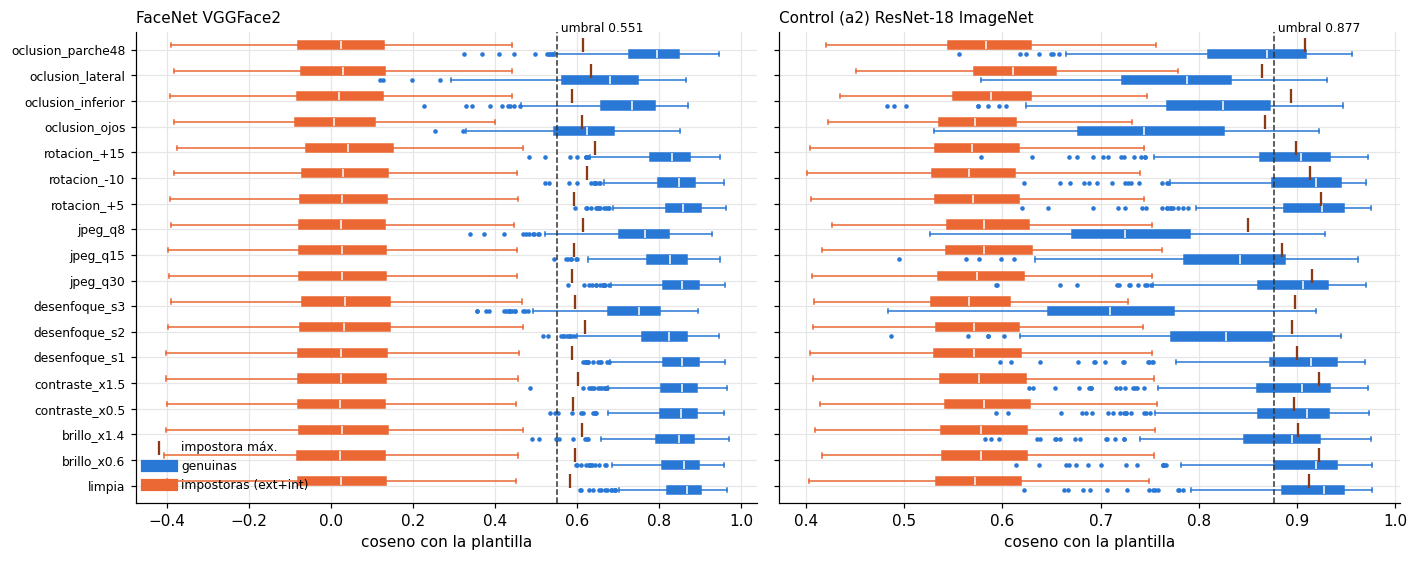

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for a, k in zip(axes, VF):
    data_g = [SCOND[k][n][0] for n in names]; data_i = [SCOND[k][n][1] for n in names]
    y = np.arange(len(names))
    a.boxplot(data_i, positions=y + 0.18, vert=False, widths=0.32, patch_artist=True, showfliers=False,
              boxprops=dict(facecolor="#eb6834", color="#eb6834"), medianprops=dict(color="white"), whiskerprops=dict(color="#eb6834"), capprops=dict(color="#eb6834"))
    a.boxplot(data_g, positions=y - 0.18, vert=False, widths=0.32, patch_artist=True, showfliers=True,
              boxprops=dict(facecolor="#2a78d6", color="#2a78d6"), medianprops=dict(color="white"), whiskerprops=dict(color="#2a78d6"),
              capprops=dict(color="#2a78d6"), flierprops=dict(marker="o", markersize=3, markerfacecolor="#2a78d6", markeredgecolor="none"))
    a.scatter([d.max() for d in data_i], y + 0.18, marker="|", s=80, color="#8a3a17", zorder=3, label="impostora máx.")
    a.axvline(UMB[k]["t_star"], color="#333", ls="--", lw=1); a.text(UMB[k]["t_star"], len(names) - 0.3, f" umbral {UMB[k]['t_star']:.3f}", fontsize=8)
    a.set_yticks(y); a.set_yticklabels(names, fontsize=8); a.invert_yaxis(); a.set_title(NOM[k], loc="left", fontsize=10); a.set_xlabel("coseno con la plantilla")
axes[0].plot([], [], color="#2a78d6", lw=8, label="genuinas"); axes[0].plot([], [], color="#eb6834", lw=8, label="impostoras (ext+int)")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(C.FIGS / "05_robustez_puntuaciones.png"); plt.show()

## 4. Coseno frente a euclídea, y plantilla media frente a varias plantillas por usuario

In [11]:
ESTR = ["media_coseno", "media_euclidea", "media_euclidea_sin_norm", "vecino_cercano", "top3_media", "kmeans3"]
rows = []
for k in VF:
    for s in ESTR:
        res = {n: scores_cond(k, n, s) for n in names}
        g0, i0, _ = res["limpia"]
        t = max(V.threshold_for_far(res[n][1], FAR_OBJ) for n in names)   # misma regla de umbral
        frr = [MT.far_frr(res[n][0], res[n][1], t)[1] for n in names]
        rows.append({"modelo": NOM[k], "estrategia": s, "EER_limpia_%": MT.eer(g0, i0)[0]*100, "AUC_limpia": MT.auc(g0, i0),
                     "margen_limpio": g0.min() - i0.max(),
                     "EER_medio_perturbadas_%": np.mean([MT.eer(res[n][0], res[n][1])[0] for n in names if n != "limpia"])*100,
                     "umbral_regla": t, "FRR_limpia_%": frr[0]*100, "FRR_medio_perturbadas_%": np.mean(frr[1:])*100, "FRR_peor_%": max(frr)*100})
estr = pd.DataFrame(rows); estr.to_csv(C.DOCS / "05_estrategias_plantilla.csv", index=False); estr.round(4)

,modelo,estrategia,EER_limpia_%,AUC_limpia,margen_limpio,EER_medio_perturbadas_%,umbral_regla,FRR_limpia_%,FRR_medio_perturbadas_%,FRR_peor_%
0,FaceNet VGGFace2,media_coseno,0.0000,1.0000,0.0240,0.6188,0.5514,0.0000,4.7830,28.5246
1,FaceNet VGGFace2,media_euclidea,0.0000,1.0000,0.0266,0.6188,-0.9472,0.0000,4.7830,28.5246
2,FaceNet VGGFace2,media_euclidea_sin_norm,0.0000,1.0000,0.0291,0.5840,-0.8827,0.0000,5.0338,30.4918
3,FaceNet VGGFace2,vecino_cercano,0.2567,1.0000,-0.1150,0.7854,0.6667,1.3115,6.9624,36.7213
4,FaceNet VGGFace2,top3_media,0.0520,1.0000,-0.0508,0.6989,0.6323,0.6557,5.6509,30.4918
5,FaceNet VGGFace2,kmeans3,0.0408,1.0000,-0.1061,0.6516,0.5955,0.3279,5.5159,32.4590
6,Control (a2) ResNet-18 ImageNet,media_coseno,2.8933,0.9962,-0.2898,7.1503,0.8769,21.9672,54.1948,97.0492
7,Control (a2) ResNet-18 ImageNet,media_euclidea,2.8933,0.9962,-0.4499,7.1503,-0.4961,21.9672,54.1948,97.0492
8,Control (a2) ResNet-18 ImageNet,media_euclidea_sin_norm,2.8896,0.9961,-0.4337,7.3565,-0.4858,21.6393,53.8862,96.7213
9,Control (a2) ResNet-18 ImageNet,vecino_cercano,2.6217,0.9968,-0.2323,6.8370,0.8819,21.9672,54.8698,97.7049


Sobre la métrica: con vectores L2-normalizados, ‖e − t‖² = 2 − 2·cos(e, t). Por eso `media_euclidea` ordena las comparaciones **exactamente**
igual que `media_coseno` y da los mismos EER, AUC y FRR; solo cambia la escala del umbral. `media_euclidea_sin_norm`, que mide la distancia a la media sin renormalizar, sí puede diferir.

## 5. Agregación de varios fotogramas (simulación para el video de la tarea 2.6)

En validación no hay video, así que un "video" de k fotogramas se **simula** con k fotos de validación distintas de la misma persona.
A cada foto se le aplica una degradación típica de cámara elegida al azar (desenfoque σ1/σ2, JPEG q30, brillo ×0,6/×1,4, rotación +5/−10, o limpia).
Son fotos más distintas entre sí que los fotogramas consecutivos de un video real, así que esto es solo una **aproximación** del beneficio de agregar.

Métodos de decisión, con el umbral propuesto:
- **1 fotograma:** el primero.
- **Media de embeddings:** se promedian los k embeddings, se renormaliza y se calcula el coseno.
- **Media de puntuaciones.**
- **Votación:** se acepta si al menos la mitad más uno de los fotogramas supera el umbral.

Se generan 40 grupos al azar (semilla 42) por cada combinación de persona e identidad reclamada:
- genuinos: cada registrada contra su propia plantilla;
- impostores externos: cada impostora de validación contra cada registrada;
- impostores internos: cada registrada contra las demás registradas.

In [12]:
VIDEO_PERT = ["limpia", "desenfoque_s1", "desenfoque_s2", "jpeg_q30", "brillo_x0.6", "brillo_x1.4", "rotacion_+5", "rotacion_-10"]
def simular(k_model, kf, n_grupos=40, seed=C.SEED):
    rng = np.random.default_rng(seed); t = UMB[k_model]["t_star"]; T = VF[k_model].T.cpu().numpy()
    out = {m: {"gen": [], "imp": []} for m in ["1 fotograma", "media embeddings", "media puntuaciones", "votación"]}
    by_person = {p: np.where(va.person.values == p)[0] for p in va.person.unique()}
    for p, idx in by_person.items():
        if len(idx) < kf: continue
        claims = [REG.index(p)] if p in REG else list(range(len(REG)))
        if p in REG: claims = claims + [c for c in range(len(REG)) if c != REG.index(p)]
        for ci, c in enumerate(claims):
            genuino = p in REG and ci == 0
            for _ in range(n_grupos if genuino else max(1, n_grupos // 8)):
                sel = rng.choice(idx, kf, replace=False); pert = rng.choice(VIDEO_PERT, kf)
                E = np.stack([EP[k_model][pp][s] for s, pp in zip(sel, pert)])
                s = E @ T[c]
                me = E.mean(0); me /= np.linalg.norm(me)
                dec = {"1 fotograma": s[0] >= t, "media embeddings": me @ T[c] >= t,
                       "media puntuaciones": s.mean() >= t, "votación": (s >= t).sum() >= kf // 2 + 1}
                for m, d in dec.items(): out[m]["gen" if genuino else "imp"].append(d)
    return out
rows = []
for k in VF:
    for kf in [1, 3, 5]:
        o = simular(k, kf)
        for m, d in o.items():
            if kf == 1 and m != "1 fotograma": continue
            g, i = np.array(d["gen"]), np.array(d["imp"])
            rows.append({"modelo": NOM[k], "fotogramas": kf, "metodo": m, "FRR_%": (~g).mean()*100, "FAR_%": i.mean()*100,
                         "n_gen": len(g), "n_imp": len(i)})
vid = pd.DataFrame(rows); vid.to_csv(C.DOCS / "05_agregacion_fotogramas.csv", index=False); vid.round(3)

,modelo,fotogramas,metodo,FRR_%,FAR_%,n_gen,n_imp
0,FaceNet VGGFace2,1,1 fotograma,0.208,0.064,960,3120
1,FaceNet VGGFace2,3,1 fotograma,0.208,0.064,960,3120
2,FaceNet VGGFace2,3,media embeddings,0.000,0.096,960,3120
3,FaceNet VGGFace2,3,media puntuaciones,0.000,0.032,960,3120
4,FaceNet VGGFace2,3,votación,0.000,0.032,960,3120
5,FaceNet VGGFace2,5,1 fotograma,0.000,0.160,960,3120
6,FaceNet VGGFace2,5,media embeddings,0.000,0.160,960,3120
7,FaceNet VGGFace2,5,media puntuaciones,0.000,0.000,960,3120
8,FaceNet VGGFace2,5,votación,0.000,0.000,960,3120
9,Control (a2) ResNet-18 ImageNet,1,1 fotograma,31.042,0.000,960,3120


## 6. Guardar el umbral propuesto en el config.json de cada paquete

In [13]:
for k, folder in PKG.items():
    p = folder / "config.json"; cfg = json.loads(p.read_text(encoding="utf-8"))
    g0, i0, _ = SCOND[k]["limpia"]; t = UMB[k]["t_star"]
    far0, frr0 = MT.far_frr(g0, i0, t)
    cfg.update({"umbral": round(t, 6), "umbral_estado": "propuesto en validación",
                "umbral_regla": f"mayor umbral con FAR <= {FAR_OBJ*100:.1f} % en validación (impostoras externas + internas) en cada una de las {len(names)} condiciones (limpia + perturbaciones); condición que lo fija: {UMB[k]['cond_peor']}",
                "umbral_validacion": {"FAR_limpia": far0, "FRR_limpia": frr0, "genuina_min_limpia": float(g0.min()),
                                      "impostora_max_limpia": float(i0.max()), "margen_a_genuina_min": float(g0.min() - t),
                                      "margen_a_impostora_max": float(t - i0.max())},
                "umbral_nota": "fijado en la tarea 2.3 solo con validación; no se recalcula en prueba (plan_evaluacion.md)"})
    p.write_text(json.dumps(cfg, indent=2, ensure_ascii=False), encoding="utf-8")
    print(NOM[k], {x: cfg[x] for x in ["umbral", "umbral_estado"]}, cfg["umbral_validacion"])
json.dump({k: {"t_star": UMB[k]["t_star"], "cond_peor": UMB[k]["cond_peor"], "t_cond": UMB[k]["t_cond"], "candidatos": UMB[k]["candidatos"]} for k in VF},
          open(C.DOCS / "05_umbral_propuesto.json", "w"), indent=2, default=float)

FaceNet VGGFace2 {'umbral': 0.551421, 'umbral_estado': 'propuesto en validación'} {'FAR_limpia': 0.0005196347709895331, 'FRR_limpia': 0.0, 'genuina_min_limpia': 0.6070001721382141, 'impostora_max_limpia': 0.5830423831939697, 'margen_a_genuina_min': 0.055579423904418945, 'margen_a_impostora_max': -0.03162163496017456}
Control (a2) ResNet-18 ImageNet {'umbral': 0.87693, 'umbral_estado': 'propuesto en validación'} {'FAR_limpia': 0.0007423353871279044, 'FRR_limpia': 0.21967213114754097, 'genuina_min_limpia': 0.622387170791626, 'impostora_max_limpia': 0.9121718406677246, 'margen_a_genuina_min': -0.25454288721084595, 'margen_a_impostora_max': -0.035241782665252686}


## 7. Conclusión (añadida tras la ejecución, sin volver a ejecutar)

- **Se mantienen** la similitud coseno (equivalente a la euclídea normalizada) y **una plantilla media por usuario**; las variantes con varias plantillas empeoran.
- **Umbral propuesto en validación para FaceNet: 0,5514**, por la regla FAR ≤ 0,1 % en la peor de 18 condiciones.
  Con imágenes limpias da FAR 0,052 % (7 de 13 471 comparaciones, todas internas: 6 Hrithik Roshan → Vijay Deverakonda y 1 Akshay Kumar → Hrithik Roshan) y FRR 0 %.
  Deja 0,056 de margen hasta la genuina mínima. Alternativa más conservadora: 0,595 (FAR limpio 0 %, pero FRR medio con perturbaciones 6,9 % frente a 4,8 %).
- **Robustez:** es robusto a brillo, contraste, JPEG ≥ q15, desenfoque σ ≤ 2 y rotación ≤ 15°, y débil ante oclusiones (ojos: FRR 28,5 %; media cara: 23,3 %) y desenfoque fuerte.
- **Control (a2):** umbral 0,8769, con FRR limpio del 22 %.
- **Video:** se propone la votación por mayoría de fotogramas. La simulación se hizo con fotos distintas y no es concluyente.
- Detalle completo en `docs/sprint2/05_validacion_ajuste.md`.